# Data split và cross-validation

Để biết model đoán tốt trên dữ liệu mới, ta giữ riêng một phần dữ liệu không dùng để học, gọi là validation. Cách chia phải giống lúc dùng thật. Ví dụ model sẽ dùng cho học sinh ở một trường mới, còn mỗi học sinh có ba bài làm trong dữ liệu. Nếu chia ngẫu nhiên từng bài làm, cùng một học sinh sẽ có mặt ở cả train lẫn validation, và điểm validation sẽ cao hơn thực tế. Bài này học các cách chia (ngẫu nhiên, theo nhóm, theo thời gian) và cross-validation: chia nhiều lần rồi lấy trung bình để kết quả bớt phụ thuộc may rủi.

> **Mục tiêu**
>
> - Chọn cách chia: ngẫu nhiên, stratified, theo nhóm hoặc theo thời gian.
> - Kiểm train và validation không trùng mẫu, không trùng nhóm, không lấy dữ liệu tương lai.
> - Dùng K-fold và tạo dự đoán out-of-fold.
> - Giữ tập test riêng, chỉ chấm sau khi đã chọn xong.

## Trước hết, hỏi mẫu mới là ai

Trước khi chia, hỏi: lúc dùng thật, mẫu mới là gì? Đoán thêm một bài làm của học sinh đã quen khác với đoán cho một học sinh chưa từng thấy. Dự báo buổi sinh hoạt tuần sau khác với đoán một buổi lấy ngẫu nhiên trong cùng giai đoạn. Mỗi câu trả lời cần một cách chia riêng:

| Tình huống cần mô phỏng | Kiểu split thường phù hợp | Điều cần kiểm |
|---|---|---|
| Mẫu độc lập, cùng phân phối | Random holdout hoặc K-fold | Không trùng bản ghi |
| Classification ít mẫu một lớp | Stratified split/K-fold | Số mẫu từng lớp đủ |
| Người, trường hoặc thiết bị chưa thấy | Group split | Group không xuất hiện ở hai phía |
| Dự đoán thời điểm tương lai | Split theo thời gian | Train đứng trước validation |

Có bài cần cả hai yêu cầu cùng lúc. Ví dụ dự đoán tháng tới cho một trường mới: validation phải là những trường không có trong train, **và** phải nằm sau train về thời gian.



**Hỏi nhanh.** Mô hình sẽ dùng để đoán cho những trường chưa có trong train. Mỗi học sinh có nhiều bản ghi. Ta nên để riêng dữ liệu validation theo đơn vị nào?

- A. Theo trường
- B. Theo học sinh, các trường vẫn trộn ở cả hai phía
- C. Theo từng bản ghi, có giữ tỉ lệ nhãn
- D. Theo thời gian, để riêng tháng cuối của mọi trường

<details><summary>Đáp án</summary>

A. Theo trường

Để riêng trọn vài trường thì validation giống đúng tình huống gặp trường mới. Chia theo học sinh tránh được trùng người, nhưng các trường vẫn có mặt ở cả hai phía, nên chưa kiểm được chuyện sang trường khác. Tháng cuối của các trường cũ thì vẫn là trường đã thấy.

</details>

## Stratified split giữ lớp, không giữ người

Classification có nhãn 1 là “cần gợi ý”, nhãn 0 là “chưa cần”. Nếu lớp 1 hiếm, chia ngẫu nhiên có thể tạo validation không có mẫu lớp 1. Khi ấy không đo được khả năng phát hiện lớp này, và một số metric còn không xác định. Chuyện này không hiếm: với 12 mẫu gồm ba nhãn 1, chọn ngẫu nhiên ba mẫu làm validation có $\binom{12}{3} = 220$ cách, trong đó $\binom{9}{3} = 84$ cách chỉ toàn nhãn 0. Xác suất validation không có nhãn 1 nào là $84/220 \approx 0.38$.

Tệ hơn nữa là dữ liệu xếp sẵn theo lớp, như 800 dòng lớp A rồi 200 dòng lớp B: cắt theo vị trí thì một phía không có lớp B nào. Vì vậy, khi dữ liệu không có yếu tố thời gian, phải xáo trộn trước khi chia.

**Stratified split** chia sao cho tỉ lệ các lớp ở mỗi phần gần bằng tỉ lệ của cả bảng; với `train_test_split` chỉ cần thêm `stratify=y`. Nó chỉ lo tỉ lệ lớp: cùng một người vẫn có thể nằm ở cả hai phía. Nếu cần cả hai, scikit-learn có `StratifiedGroupKFold`.

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

labels = np.array([1, 1, 1] + [0] * 9)
row_ids = np.arange(len(labels))
train_ids, valid_ids = train_test_split(
    row_ids, test_size=0.25, random_state=13, stratify=labels
)
print("Số mẫu train/valid:", len(train_ids), len(valid_ids))
print("Số nhãn 1 train/valid:", labels[train_ids].sum(), labels[valid_ids].sum())
print("Trùng hàng:", len(set(train_ids) & set(valid_ids)))

Số mẫu train/valid: 9 3
Số nhãn 1 train/valid: 2 1
Trùng hàng: 0


Validation có ba mẫu nên không thể có đúng 25% mẫu lớp 1; code giữ một mẫu lớp 1 ở validation, hai ở train. Khi chia thành nhiều phần, lớp hiếm nhất phải có ít nhất bằng số phần thì phần nào cũng có lớp ấy.

**Hỏi nhanh.** Mỗi học sinh có nhiều bài làm trong dữ liệu. Ta dùng stratified split. Cách chia này bảo đảm được điều gì?

- A. Không học sinh nào có bài ở cả hai phía
- B. Bài trong validation đều làm muộn hơn bài trong train
- C. Tỉ lệ nhãn ở hai phía gần nhau, và chỉ có vậy
- D. Mỗi học sinh có đúng một bài trong validation

<details><summary>Đáp án</summary>

C. Tỉ lệ nhãn ở hai phía gần nhau, và chỉ có vậy

Stratified split chỉ lo tỉ lệ các lớp. Muốn không trùng người thì cần chia theo nhóm. Muốn không dùng dữ liệu tương lai thì cần chia theo thời gian. Đây là ba yêu cầu khác nhau, phải kiểm riêng từng cái.

</details>

## Group split: kiểm giao của tập người

Code dưới tạo sáu học sinh, mỗi người ba bản ghi. `groups` đi cùng hàng để chỉ ra người sở hữu bản ghi; không cần đưa mã người vào feature. Trước tiên nhìn một random split, rồi kiểm ba vòng `GroupKFold`.

In [ ]:
from sklearn.model_selection import GroupKFold

groups = np.repeat(np.arange(6), 3)
X_group = np.zeros((18, 1))                 # chỉ dùng để minh họa chỉ số
y_group = np.repeat([0, 1, 0, 1, 0, 1], 3)
all_ids = np.arange(18)
train_ids, valid_ids = train_test_split(
    all_ids, test_size=1/3, random_state=13
)
shared = set(groups[train_ids]) & set(groups[valid_ids])
print("Random split, người trùng:", sorted(map(int, shared)))

group_cv = GroupKFold(n_splits=3)
for fold, (train_ids, valid_ids) in enumerate(
    group_cv.split(X_group, y_group, groups), start=1
):
    shared = set(groups[train_ids]) & set(groups[valid_ids])
    assert not shared
    print(f"Fold {fold}: valid groups={sorted(map(int, set(groups[valid_ids])))}, trùng={len(shared)}")

Random split, người trùng: [0, 1, 2, 3, 5]
Fold 1: valid groups=[2, 5], trùng=0
Fold 2: valid groups=[1, 4], trùng=0
Fold 3: valid groups=[0, 3], trùng=0


Chia ngẫu nhiên làm năm trong sáu người có bài ở cả hai phía. Với `GroupKFold`, mỗi vòng không có người nào chung giữa train và validation. Để ý: phải kiểm giao của **tập người**, không chỉ giao của chỉ số hàng, vì hai hàng khác nhau vẫn có thể của cùng một người.

`GroupKFold` nhận thêm mảng `groups` và bảo đảm mỗi nhóm chỉ nằm ở một phía. Nhóm có thể là mọi ảnh của một bệnh nhân, mọi bản ghi của một học sinh. Nếu để người đã thấy lẫn vào validation, điểm sẽ cao hơn thực tế: model nhận ra người quen chứ chưa chắc làm tốt với người lạ. Vài trường hợp khác cũng cần gom nhóm:

- Cùng một ảnh lưu thành nhiều bản: cắt, đổi cỡ, đổi tên file. Gom các bản này vào một nhóm.
- Các khung hình liền nhau của một video gần như giống hệt nhau: chia theo video, không xáo từng khung.

Chia theo nhóm có thể làm tỉ lệ nhãn giữa các fold lệch nhau, nhất là khi ít nhóm hoặc có nhóm rất lớn, nên hãy in số mẫu và số nhãn của từng fold để biết.

**Hỏi nhanh.** Bộ ảnh bài làm viết tay có nhiều ảnh là bản cắt, bản xoay nhẹ, hoặc bản chụp lại từ cùng một tờ giấy. Chia ngẫu nhiên theo ảnh thì validation đúng 99%, nhưng gặp bài của lớp khác chỉ đúng 80%. Ta nên sửa cách chia thế nào?

- A. Chia sao cho tỉ lệ nhãn ở hai phía bằng nhau
- B. Gom các ảnh cùng một tờ giấy thành một nhóm, rồi chia theo nhóm
- C. Chia lại ngẫu nhiên với seed khác cho điểm ổn định hơn
- D. Bỏ các ảnh cắt khỏi validation nhưng giữ trong train

<details><summary>Đáp án</summary>

B. Gom các ảnh cùng một tờ giấy thành một nhóm, rồi chia theo nhóm

Khi các bản gần giống nhau nằm ở cả hai phía, validation gần như chấm lại đúng ảnh đã học. Gom theo tờ giấy thì validation giống tình huống “bài mới” hơn. Nếu muốn đo khả năng đọc chữ của người mới, ta gom theo người viết. Bỏ ảnh cắt khỏi validation chưa đủ, vì tờ giấy gốc vẫn có mặt ở cả hai phía.

</details>

## Thời gian: quá khứ học, tương lai chấm

Muốn dự báo buổi tuần sau, model chỉ được học từ những buổi đã diễn ra trước đó. Nếu xáo trộn rồi chia, train có thể chứa các tuần nằm sau validation: model được học từ tương lai, điều không thể có lúc dùng thật.



`TimeSeriesSplit` chia theo thời gian, mỗi vòng train dài thêm. Code dưới dùng 12 tuần đã sắp thứ tự, mỗi lần validation hai tuần; `gap=1` bỏ một tuần sát ranh giới giữa train và validation. Ở bài thật, gap dài bao nhiêu phải tính theo lúc nào nhãn được biết; mục sau có ví dụ.

In [ ]:
from sklearn.model_selection import TimeSeriesSplit

weeks = np.arange(12)
time_cv = TimeSeriesSplit(n_splits=3, test_size=2, gap=1)
for fold, (train_ids, valid_ids) in enumerate(time_cv.split(weeks), start=1):
    assert weeks[train_ids].max() < weeks[valid_ids].min()
    print(f"Fold {fold}: train={train_ids.tolist()}, valid={valid_ids.tolist()}")

Fold 1: train=[0, 1, 2, 3, 4], valid=[6, 7]
Fold 2: train=[0, 1, 2, 3, 4, 5, 6], valid=[8, 9]
Fold 3: train=[0, 1, 2, 3, 4, 5, 6, 7, 8], valid=[10, 11]


Dùng số liệu của tuần trước làm feature, như số đăng ký tuần trước, là được, vì lúc dự báo tuần này đã biết số đó. Điều cần kiểm là: feature hay nhãn của train có chứa thông tin mà lúc dự báo validation chưa thể biết không.

Hai lưu ý: `TimeSeriesSplit` không tự đọc cột ngày, nên phải sắp các hàng theo thời gian trước. Và nó chia theo **số hàng**, nên nếu các hàng cách nhau không đều, mỗi phần validation có thể dài ngắn khác nhau về thời gian; khi đó nên tự chia theo mốc ngày.

**Hỏi nhanh.** Nhãn của mỗi hàng là tổng số người đến trong ba tuần tiếp theo. Ta chỉ bảo đảm ngày bắt đầu của mọi hàng train sớm hơn validation. Như vậy đã đủ chưa?

- A. Đủ, vì ngày bắt đầu đã đúng thứ tự
- B. Đủ, nếu giữ thêm tỉ lệ nhãn
- C. Chưa, phải bỏ hẳn cột ngày khỏi feature
- D. Chưa, vì nhãn của train có thể tính cả những tuần thuộc validation

<details><summary>Đáp án</summary>

D. Chưa, vì nhãn của train có thể tính cả những tuần thuộc validation

Một hàng train bắt đầu sát ranh giới thì nhãn của nó tính cả ba tuần sau, mà các tuần ấy đã thuộc validation. Phải kiểm xem nhãn thật sự biết được vào lúc nào. Có khi phải chừa một khoảng trống (gap) ở ranh giới, hoặc bỏ những hàng có ba tuần mục tiêu vắt qua ranh giới.

</details>



## K-fold và dự đoán out-of-fold

**K-fold cross-validation** chia dữ liệu thành $K$ phần bằng nhau, gọi là fold. Làm $K$ vòng: mỗi vòng giữ một fold để chấm và học trên $K - 1$ fold còn lại. Sau $K$ vòng, mẫu nào cũng được chấm đúng một lần, bởi model chưa học nó.

- So với chia một lần, kết quả ổn định hơn vì dùng hết dữ liệu để chấm, nhất là khi dữ liệu ít.
- Đổi lại phải huấn luyện $K$ lần; với model lớn và dữ liệu nhiều, người ta thường chỉ chia một lần.
- $K$ bằng số mẫu gọi là leave-one-out (LOOCV): mỗi vòng giữ riêng đúng một mẫu, $n$ mẫu thì $n$ vòng.

Điểm cuối thường là trung bình điểm của các fold:

$$\bar s=\frac1K\sum_{k=1}^{K}s_k.$$

Một cách khác là gộp dự đoán của mọi fold rồi tính điểm một lần. Hai cách cho kết quả khác nhau khi các fold không bằng nhau, hoặc với metric như F1 (bài 1.5); nên ghi rõ đang báo cách nào.

Code dưới tạo dữ liệu phân loại giả 96 mẫu, bốn feature, chia ba fold stratified. Model `LogisticRegression` trả về xác suất thuộc lớp 1 (bài 2.3 sẽ học model này). Ghép dự đoán của ba vòng lại được một dự đoán cho mỗi mẫu, đều do model chưa học mẫu đó tạo ra; gọi là **dự đoán out-of-fold** (OOF).

In [ ]:
from sklearn.datasets import make_classification
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

X, y = make_classification(
    n_samples=96, n_features=4, n_informative=3,
    n_redundant=0, random_state=13,
)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=13)
oof_probability = np.full(len(y), np.nan)
times_scored = np.zeros(len(y), dtype=int)
fold_scores = []
for fold, (train_ids, valid_ids) in enumerate(cv.split(X, y), start=1):
    model = LogisticRegression(max_iter=500).fit(X[train_ids], y[train_ids])
    probability = model.predict_proba(X[valid_ids])[:, 1]
    oof_probability[valid_ids] = probability       # ghi về đúng vị trí gốc
    times_scored[valid_ids] += 1
    score = accuracy_score(y[valid_ids], probability >= 0.5)
    fold_scores.append(score)
    print(f"Fold {fold}: n={len(valid_ids)}, accuracy={score:.3f}")
assert np.all(times_scored == 1)
assert np.isfinite(oof_probability).all()
print("OOF shape:", oof_probability.shape)
print(f"Mean fold accuracy={np.mean(fold_scores):.3f}")
print(f"Pooled OOF accuracy={accuracy_score(y, oof_probability >= 0.5):.3f}")

Fold 1: n=32, accuracy=0.969
Fold 2: n=32, accuracy=0.906
Fold 3: n=32, accuracy=0.906
OOF shape: (96,)
Mean fold accuracy=0.927
Pooled OOF accuracy=0.927


`[:, 1]` lấy cột xác suất của lớp 1. Điều quan trọng là code ghi dự đoán vào đúng vị trí `valid_ids` của mảng OOF, chứ không nối các đoạn theo thứ tự fold; nối như vậy thì dự đoán bị lệch sang hàng khác. Mảng `times_scored` kiểm rằng không hàng nào bị bỏ sót hay chấm hai lần.



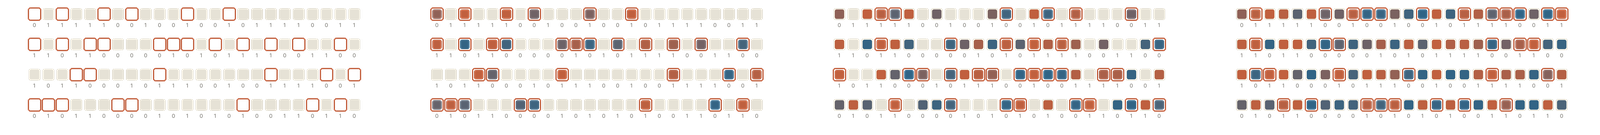

Với `TimeSeriesSplit`, các tuần đầu chỉ làm train, không bao giờ được chấm, nên mảng OOF có những ô trống. Đánh dấu hàng nào đã được chấm và chỉ tính điểm trên những hàng đó; không lấy dự đoán trên train để lấp chỗ trống.

**Hỏi nhanh.** Một đội dùng điểm OOF để chọn feature, rồi lại dùng nó để chọn giữa nhiều mô hình. Điểm OOF của phương án thắng còn được coi là điểm test độc lập không?

- A. Còn, vì mỗi mẫu không nằm trong train của fold chấm nó
- B. Còn, nếu mọi hàng đều được chấm đúng một lần
- C. Không, vì các lựa chọn đều đã dựa vào điểm OOF
- D. Còn, nếu tăng số fold để bớt nhiễu

<details><summary>Đáp án</summary>

C. Không, vì các lựa chọn đều đã dựa vào điểm OOF

OOF bảo đảm mỗi mẫu được chấm bởi một mô hình chưa học mẫu ấy. Nhưng cả việc chọn feature lẫn chọn mô hình đều dựa vào chính điểm này, nên phương án thắng đã được chọn một phần nhờ hợp với nhiễu của OOF. Muốn đánh giá cả quy trình chọn, ta giữ một tập test riêng, hoặc dùng nested CV, tức thêm một vòng chia ngoài chỉ để chấm.

</details>

## Khi đi thi

- Hỏi trước mẫu mới là ai: một hàng mới, một người mới hay một thời điểm sau. Từ đó chọn chia ngẫu nhiên, theo nhóm hay theo thời gian.
- Dùng cùng các fold cho mọi phương án đem so.
- In kiểm từng fold: số mẫu, tỉ lệ lớp, giao của các nhóm, khoảng thời gian.

## Tóm tắt

- Chia dữ liệu theo cách model sẽ được dùng, không chọn cách cho điểm cao nhất.
- Stratified giữ tỉ lệ lớp; chia theo nhóm để validation toàn người hoặc trường mới; chia theo thời gian để học quá khứ, chấm tương lai.
- Dự đoán OOF phải ghi vào đúng chỉ số hàng.
- Cross-validation để chọn model; test riêng để chấm sau khi đã chọn.

## Kiểm tra cuối bài

**Câu 1.** Mô hình sẽ dùng cho những người chưa có trong dữ liệu, mà mỗi người có nhiều bản ghi. Ta nên chia dữ liệu thế nào?

- A. Chia theo nhóm, mỗi người là một nhóm
- B. Chia từng bản ghi, giữ tỉ lệ nhãn, không quan tâm người
- C. Chia ngẫu nhiên từng bản ghi thành K fold, vì như vậy có nhiều hàng hơn
- D. Dùng TimeSeriesSplit theo thứ tự dòng, dù không phải bài dự báo tương lai

<details><summary>Đáp án</summary>

A. Chia theo nhóm, mỗi người là một nhóm

Chia theo người thì mọi bản ghi của một người nằm cùng một phía, nên validation toàn là người mới, đúng tình huống dùng thật. Chia ngẫu nhiên từng bản ghi thì cùng một người có mặt ở cả hai phía. TimeSeriesSplit trả lời câu hỏi về tương lai, không phải về người mới.

</details>

**Câu 2.** Hai cách làm trên cùng một bộ dữ liệu.

**A**: chia 70% train, 30% test. Lặp 50 vòng “train, xem điểm test, chỉnh mô hình”, rồi báo điểm test cao nhất là 94.2%.

**B**: chia 60% train, 20% validation, 20% test. Chỉnh mô hình theo validation, rồi chấm test đúng một lần, được 91.8%.

Con số nào đáng tin hơn để ước lượng mô hình làm tốt đến đâu trên dữ liệu mới?

- A. Của A, vì nhiều dữ liệu train hơn và tìm kiếm kỹ hơn
- B. Của A, vì xem test 50 lần thì ổn định hơn một lần
- C. Của B, vì test của B không tham gia việc chọn
- D. Như nhau, vì hai tập test gần bằng nhau

<details><summary>Đáp án</summary>

C. Của B, vì test của B không tham gia việc chọn

Sau 50 vòng chỉnh theo test, tập 30% của A thực chất đã thành validation. Cấu hình thắng được chọn một phần vì nó hợp với nhiễu của đúng những mẫu ấy, và lặp lại không thêm được dữ liệu độc lập nào. B chỉ nhìn test một lần, nên 91.8% mới là con số sạch, dù trông thấp hơn.
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 303](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=116)

</details>

**Câu 3.** Train có học sinh của trường 1 và 2. Validation có học sinh của trường 2 và 3. Không có học sinh nào ở cả hai phía. Cách chia này có kiểm được khả năng đoán cho trường mới không?

- A. Chưa, vì trường 2 có mặt ở cả train và validation
- B. Có, vì đã chia theo từng học sinh
- C. Có, vì các trường ở hai phía không giống hệt nhau
- D. Có, nếu tỉ lệ nhãn ở hai phía bằng nhau

<details><summary>Đáp án</summary>

A. Chưa, vì trường 2 có mặt ở cả train và validation

Muốn kiểm với trường mới thì phải chia theo trường. Không trùng học sinh chưa có nghĩa là không trùng trường: trường 2 vẫn nằm ở cả hai phía.

</details>

**Câu 4.** Lớp hiếm chỉ có 4 mẫu. Ta muốn chia thành 5 fold validation không chồng lên nhau, fold nào cũng có ít nhất một mẫu của lớp hiếm. Làm được không?

- A. Được, nếu xáo dữ liệu đủ nhiều lần
- B. Được, bằng cách cho một mẫu hiếm vào hai fold
- C. Được, vì stratified split giữ tỉ lệ lớp
- D. Không được, vì cần ít nhất 5 mẫu của lớp hiếm

<details><summary>Đáp án</summary>

D. Không được, vì cần ít nhất 5 mẫu của lớp hiếm

Năm fold không chồng lên nhau, fold nào cũng có lớp hiếm, thì cần ít nhất năm mẫu khác nhau. Cho một mẫu vào hai fold là các fold đã chồng lên nhau. Xáo dữ liệu hay stratified split đều không tạo thêm mẫu được.

</details>

**Câu 5.** Dữ liệu dự báo có cột `time`, nhưng các hàng đang bị xáo trộn. Trước khi dùng TimeSeriesSplit, ta phải làm gì để fold nào cũng học quá khứ, đoán tương lai?

- A. Sắp theo `y` để validation có nhãn mới hơn
- B. Giữ thứ tự đang xáo, chỉ đổi `random_state`
- C. Sắp các hàng tăng dần theo `time`, rồi kiểm khoảng trống ở ranh giới
- D. Không cần làm gì, vì TimeSeriesSplit tự sắp theo cột `time`

<details><summary>Đáp án</summary>

C. Sắp các hàng tăng dần theo `time`, rồi kiểm khoảng trống ở ranh giới

TimeSeriesSplit cắt theo thứ tự hàng, không tự đọc cột `time`, nên phải sắp các hàng theo thời gian trước. Sau đó vẫn phải kiểm lúc nào thì nhãn và feature thật sự biết được, và chừa khoảng trống (gap) nếu cần.

</details>

**Câu 6.** Hai fold validation có 10 và 30 mẫu, accuracy lần lượt là 0.6 và 0.8. Gộp cả 40 dự đoán OOF lại thì accuracy là bao nhiêu?

- A. 1.40
- B. 0.75
- C. 0.80
- D. 0.70

<details><summary>Đáp án</summary>

B. 0.75

Fold đầu đúng $0.6 \cdot 10 = 6$ mẫu, fold sau đúng $0.8 \cdot 30 = 24$ mẫu. Tổng cộng đúng 30 trên 40, nên accuracy gộp là 0.75. 0.70 là trung bình đều của hai fold, một cách tính khác, coi fold 10 mẫu nặng ngang fold 30 mẫu.

</details>

**Câu 7.** Bài phân loại nhị phân. Mỗi fold cho ra `predict_proba(X_valid)[:, 1]`, và các fold không lấy hàng theo thứ tự. Ta ghi các dự đoán vào mảng OOF thế nào để mỗi số nằm đúng hàng của nó?

- A. Ghi lần lượt vào các vị trí đầu của mảng OOF
- B. Ghi vào đúng các vị trí `valid_idx` của mảng OOF
- C. Sắp các xác suất tăng dần, rồi ghép với `y` theo thứ tự cũ
- D. Nối các mảng dự đoán lại, rồi so với `y` theo thứ tự cũ

<details><summary>Đáp án</summary>

B. Ghi vào đúng các vị trí `valid_idx` của mảng OOF

Mỗi dự đoán phải ghi vào đúng chỉ số gốc của hàng validation, tức là `oof[valid_idx] = ...`. Nối các mảng theo thứ tự fold thì đủ độ dài, nhưng dự đoán bị lệch sang hàng khác. So với `y` khi đó cho kết quả sai mà không báo lỗi gì.

</details>

**Câu 8.** Với TimeSeriesSplit, các hàng đầu tiên chưa bao giờ nằm trong validation. Ở những hàng ấy, mảng OOF nên ghi gì?

- A. Ghi nhãn thật cho đủ hàng khi chấm
- B. Ghi dự đoán của mô hình trên train
- C. Ghi 0 cho đủ shape, rồi chấm mọi hàng
- D. Đánh dấu là chưa chấm, chỉ tính trên các hàng có OOF

<details><summary>Đáp án</summary>

D. Đánh dấu là chưa chấm, chỉ tính trên các hàng có OOF

Ghi nhãn thật thì điểm đẹp giả. Dự đoán trên train là của mô hình đã thấy nhãn, nên không phải OOF. Ghi 0 là bịa ra một dự đoán và kéo điểm sai đi. Ta giữ một mặt nạ đánh dấu hàng nào đã được chấm, rồi chỉ tính metric trên những hàng đó.

</details>

**Câu 9.** Câu nào mô tả đúng K-fold cross-validation cho linear regression với một feature $x$?

- A. Sắp theo $x$, cắt thành $K$ khối liền nhau, lần lượt giữ lại một khối
- B. Học một lần trên toàn bộ dữ liệu, rồi chấm $K$ lần
- C. Học trên mọi tập con cỡ $K$, lấy trung bình lỗi trên một tập test riêng
- D. Chia ngẫu nhiên thành $K$ phần, mỗi vòng giữ lại một phần để chấm

<details><summary>Đáp án</summary>

D. Chia ngẫu nhiên thành $K$ phần, mỗi vòng giữ lại một phần để chấm

Nếu cắt theo $x$ đã sắp, khối đầu và khối cuối luôn nằm ngoài khoảng $x$ của train. Khi đó validation đo khả năng đoán ra ngoài vùng đã thấy, không phải đoán mẫu mới giống dữ liệu cũ. Học trên toàn bộ rồi chấm lại chính các điểm ấy thì không có gì được giữ riêng.
Phỏng theo: [CMU 10-601 · Practice Problems, Exam 1 · Q3.4](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam1_practice_problems.pdf#page=16)

</details>

**Câu 10.** Ta dự báo lúc 8 giờ sáng thứ Hai. Feature A là tổng số đăng ký của tuần trước. Feature B là tổng số người đến trong chính tuần đang dự báo. Cả hai đều có sẵn trong bảng lịch sử, và lúc 8 giờ ta đã biết A. Được dùng feature nào?

- A. Chỉ A, vì lúc dự báo chưa thể biết B
- B. Cả A và B, vì cả hai đều có trong bảng lịch sử
- C. Chỉ B, vì B gần với nhãn hơn
- D. Không dùng A, vì dữ liệu tuần trước của các hàng có thể trùng nhau

<details><summary>Đáp án</summary>

A. Chỉ A, vì lúc dự báo chưa thể biết B

Một feature dùng được hay không là tùy vào lúc nó có sẵn. B có trong bảng lịch sử vì được ghi lại sau, nhưng lúc 8 giờ sáng thứ Hai của một tuần mới thì B chưa tồn tại.

</details>

## Đọc thêm

- [scikit-learn — Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html). Tra sự khác nhau giữa KFold, StratifiedKFold, GroupKFold và TimeSeriesSplit.
- James và cộng sự — [An Introduction to Statistical Learning](https://www.statlearning.com/), chương 5. Đọc về holdout, K-fold và sai số của phép ước lượng.
- [scikit-learn — Nested versus non-nested cross-validation](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html). Xem vì sao chọn cấu hình và đánh giá quy trình là hai việc khác nhau.